# **🤑💵💰 Billionaires Analysis**

## **1 · Import the tools**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'FreeSerif', 'DejaVu Serif']

## **2 · Load and inspect the table**

In [2]:
data_frame = pd.read_csv("Billionaire.csv")
data_frame.head()

,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,$177 B,United States,Amazon,1,57.0,Technology
1,Elon Musk,$151 B,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,$150 B,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,$124 B,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,$97 B,United States,Facebook,5,36.0,Technology


## **3 · Check for missing values**

In [3]:
data_frame.isnull().sum()

Name         0
NetWorth     0
Country      0
Source       0
Rank         0
Age         79
Industry     0
dtype: int64

### **Remove incomplete rows**

In [4]:
data_frame = data_frame.dropna()

## **3 · Clean the net worth column**

In [5]:
data_frame["NetWorth"] = data_frame["NetWorth"].str.strip("$")
data_frame["NetWorth"] = data_frame["NetWorth"].str.strip("B")
data_frame["NetWorth"] = data_frame["NetWorth"].astype(float)

In [6]:
data_frame.head()

,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,177.0,United States,Amazon,1,57.0,Technology
1,Elon Musk,151.0,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,150.0,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,124.0,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,97.0,United States,Facebook,5,36.0,Technology


## **4 · Rank billionaires by net worth**

In [7]:
df = data_frame.sort_values(by = ["NetWorth"], ascending=False).head(20)
df

,Name,NetWorth,Country,Source,Rank,Age,Industry
0,Jeff Bezos,177.0,United States,Amazon,1,57.0,Technology
1,Elon Musk,151.0,United States,"Tesla, SpaceX",2,49.0,Automotive
2,Bernard Arnault & family,150.0,France,LVMH,3,72.0,Fashion & Retail
3,Bill Gates,124.0,United States,Microsoft,4,65.0,Technology
4,Mark Zuckerberg,97.0,United States,Facebook,5,36.0,Technology
5,Warren Buffett,96.0,United States,Berkshire Hathaway,6,90.0,Finance & Investments
6,Larry Ellison,93.0,United States,software,7,76.0,Technology
7,Larry Page,91.5,United States,Google,8,48.0,Technology
8,Sergey Brin,89.0,United States,Google,9,47.0,Technology
9,Mukesh Ambani,84.5,India,diversified,10,63.0,Diversified


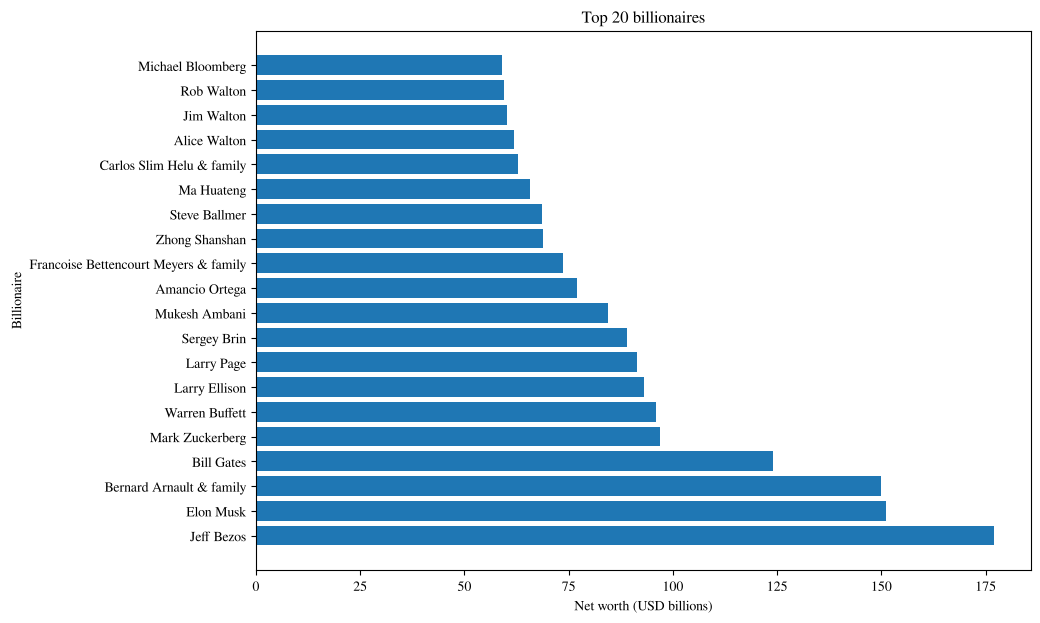

In [8]:
plt.figure(figsize=(10, 7))
plt.barh(df["Name"], df["NetWorth"])
plt.title("Top 20 billionaires")
plt.xlabel("Net worth (USD billions)")
plt.ylabel("Billionaire")
plt.show()

## **5 · Compare sources of wealth**

In [9]:
df = data_frame["Source"].value_counts().head().reset_index()
df

,Source,count
0,real estate,169
1,pharmaceuticals,96
2,investments,89
3,diversified,78
4,software,61


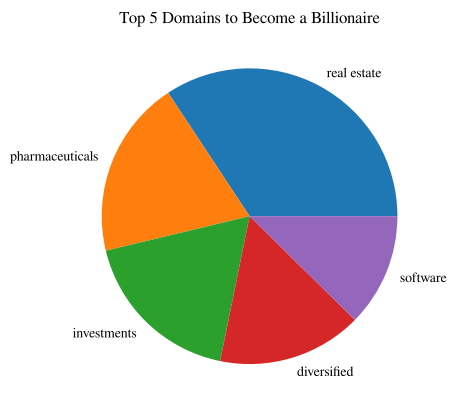

In [10]:
plt.pie(df["count"], labels=df["Source"])
plt.title("Top 5 Domains to Become a Billionaire")
plt.show()

## **6 · Compare industries**

### **Q2 (a) · Load and inspect**

In [11]:
billionaires = pd.read_csv('Billionaire.csv')
print('Rows and columns:', billionaires.shape)
billionaires.info()

Rows and columns: (2755, 7)
<class 'pandas.DataFrame'>
RangeIndex: 2755 entries, 0 to 2754
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Name      2755 non-null   str    
 1   NetWorth  2755 non-null   str    
 2   Country   2755 non-null   str    
 3   Source    2755 non-null   str    
 4   Rank      2755 non-null   int64  
 5   Age       2676 non-null   float64
 6   Industry  2755 non-null   str    
dtypes: float64(1), int64(1), str(5)
memory usage: 150.8 KB


In [12]:
print('Missing values:')
print(billionaires.isna().sum())

Missing values:
Name         0
NetWorth     0
Country      0
Source       0
Rank         0
Age         79
Industry     0
dtype: int64


Only `Age` has missing values (79 rows). `Industry` is complete, so all 2,755 billionaires are counted here. The cleaned table used in earlier sections dropped those 79 rows.

### **Q2 (b) · Count billionaires per industry**

In [13]:
industry_counts = billionaires['Industry'].value_counts().sort_values(ascending=False)
print('Industries:', industry_counts.size)
industry_counts.rename('billionaires').to_frame()

Industries: 18


,billionaires
Industry,
Finance & Investments,371
Technology,365
Manufacturing,331
Fashion & Retail,273
Healthcare,221
Food & Beverage,219
Real Estate,215
Diversified,188
Energy,100


### **Q2 (c) · Top 10 industries and Other**

In [14]:
top_industries = industry_counts.head(10).copy()
top_industries['Other'] = industry_counts.iloc[10:].sum()
print('Total counted:', top_industries.sum(), 'of', len(billionaires))
top_industries.rename('billionaires').to_frame()

Total counted: 2755 of 2755


,billionaires
Industry,
Finance & Investments,371
Technology,365
Manufacturing,331
Fashion & Retail,273
Healthcare,221
Food & Beverage,219
Real Estate,215
Diversified,188
Energy,100


**Other** combines the 8 smallest industries (Service to Sports) and is placed last, because its combined count would otherwise rank first.

### **Q2 (d) · Pie chart**

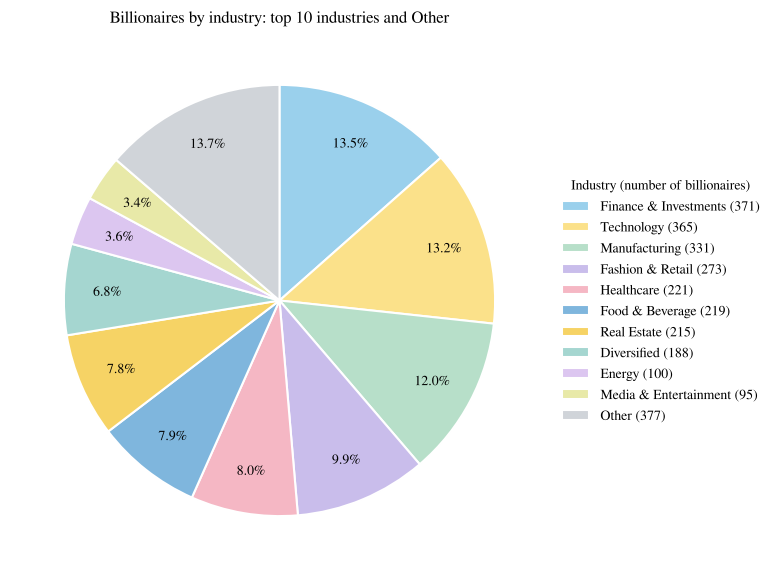

In [15]:
colors = ['#9AD0EC', '#FBE18A', '#B7DFC9', '#C9BDEB', '#F5B7C4', '#7FB6DD', '#F6D365', '#A5D6D0', '#DCC6F0', '#E8E9A8', '#D0D4D9']
total = top_industries.sum()

plt.figure(figsize=(10, 7))
wedges, texts, autotexts = plt.pie(
    top_industries.values,
    colors=colors,
    startangle=90,
    counterclock=False,
    autopct='%1.1f%%',
    pctdistance=0.8,
    wedgeprops={'edgecolor': 'white', 'linewidth': 1.5}
)
plt.legend(
    wedges,
    [f'{name} ({count})' for name, count in top_industries.items()],
    title='Industry (number of billionaires)',
    loc='center left',
    bbox_to_anchor=(1, 0.5),
    frameon=False
)
plt.title('Billionaires by industry: top 10 industries and Other')
plt.show()

Finance & Investments (371) and Technology (365) lead, followed by Manufacturing (331) and Fashion & Retail (273). The remaining 8 industries together hold 377 billionaires (13.7%), more than any single industry.

## **7 · Compare countries**

In [16]:
df = data_frame["Country"].value_counts().head().reset_index()
df

,Country,count
0,United States,720
1,China,610
2,India,134
3,Russia,118
4,Germany,115


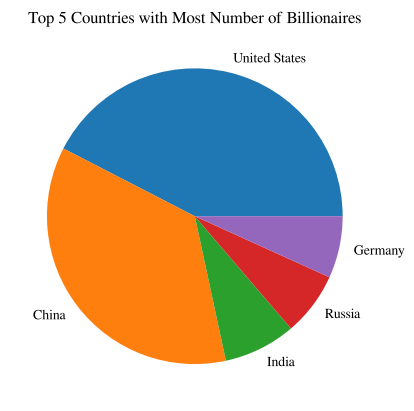

In [17]:
plt.pie(df["count"], labels=df["Country"])
plt.title("Top 5 Countries with Most Number of Billionaires")
plt.show()